# 04b — My approach v2: + Binoculars and a human-vs-fusion specialist

Extends **04** (kept unchanged) with E1b Binoculars features and one more stacking input: the 03c human-vs-fusion specialist. Reference = the best single 3-class encoder among those attached (03 / 03b) on the fixed val split. Experiments, each compared with that reference:
- **E1 — Perplexity + stylometry features.** An open-weight causal LM (`Qwen/Qwen2.5-0.5B`, multilingual) scores every token; we aggregate log-probs, ranks, entropy, a Fast-DetectGPT-style curvature score and **segment-level variability** (fusion = partly rewritten → some segments look human, some AI). LightGBM on these features only.
- **E1b — Binoculars.** A second LM (`Qwen2.5-0.5B-Instruct`) next to the base one: the ratio of the instruct model's perplexity to the cross-perplexity between the two models (Hans et al., 2024), globally and per 64-token segment.
- **E2 — Stacking ensemble.** LightGBM over all base models' val outputs — encoder logits (03, and 03b with its window-level statistics), 03c specialist logits, TF-IDF scores (02, 02b) — plus E1 features, trained with 5-fold group CV *inside the val split* (out-of-fold predictions → no leakage; base models never saw val).
- **E3 — Class weights for macro-F1.** Per-class multipliers on stacked probabilities, tuned on half the val folds and checked on the other half.

**Run on Kaggle**
1. *Create → New Notebook → File → Import Notebook* → upload this file.
2. *Settings*: Accelerator **GPU T4 x2**, Internet **On** (downloads Hugging Face weights).
3. *Add Input*: competition **ai-generated-text-detection-hw3-ucu-ai-2026**, and the outputs of **02_baseline** and **03_encoder** (required) plus **02b_baseline_full**, **03b_encoder_full**, **03c_encoder_human_fusion** (optional: used automatically when attached). Also attach the output of **04_my_approach** (its cached LM features are reused) and, on a re-run, of the previous 04b run — the LM and Binoculars features are then loaded instead of recomputed.
4. *Save Version → Save & Run All (Commit)*. **ETA: ~4.5 h first run (LM features ≈ 2 h, Binoculars ≈ 2–2.5 h); a re-run recomputes only features missing from the attached previous output (~2.5 h if only Binoculars is new, ~15 min if both are cached).**

**Copy back into the repo** (from the version's *Output* tab):
- this notebook with outputs → `notebooks/04b_my_approach_v2.ipynb`
- `results_summary_04b.csv`, `cm_*.png` → `reports/` and `reports/figures/`
- keep `stacker_04b.joblib`, `stack_val_features_04b.csv`, `lm_feats_*.csv`, `bino_feats_*.csv` only on Kaggle (inputs of 05 / a 04 re-run)


In [1]:
import os, glob, re, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SMOKE = bool(os.environ.get('SMOKE'))  # tiny local dry-run of the whole notebook; never set on Kaggle
OUT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
OUT.mkdir(exist_ok=True)
SEED, LABELS = 42, ['human', 'ai', 'fusion']
L2I = {l: i for i, l in enumerate(LABELS)}

def find(name):
    """Locate an input file in attached Kaggle inputs (or ../data locally)."""
    for root in ['/kaggle/input', '../data', str(OUT)]:
        hits = sorted(glob.glob(f'{root}/**/{name}', recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'{name} not found: attach the inputs listed at the top of this notebook')

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")  # the competition metric

def report(y_true, y_pred, title):
    """Per-class metrics + normalized confusion matrix (labels are class indices)."""
    print(f'{title}: macro-F1 = {macro_f1(y_true, y_pred):.4f}')
    print(classification_report(y_true, y_pred, target_names=LABELS, digits=4))
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap='Blues', values_format='.3f')
    plt.title(title); plt.grid(False)
    plt.savefig(OUT / f"cm_{re.sub(r'[^a-z0-9]+', '_', title.lower())}.png", dpi=120, bbox_inches='tight'); plt.show()

def f1_by(df, pred_col, by):
    return df.groupby(by).apply(lambda d: macro_f1(d.y, d[pred_col])).round(4).rename('macro_f1').to_frame().join(df[by].value_counts().rename('n'))

train = pd.read_csv(find('train.csv'))
test = pd.read_csv(find('test.csv'))
sub = pd.read_csv(find('sample_submission.csv'))
if SMOKE:
    test = test.head(300); sub = sub[sub.id.isin(test.id)]
train['y'] = train.label.map(L2I)
print(train.shape, test.shape)

(272352, 6) (25000, 4)


In [2]:
split = pd.read_csv(find('split.csv'))
train = train.merge(split, on='id', validate='1:1')
val = train[train.is_val].reset_index(drop=True)
print('val rows:', len(val), '| fixed train sample:', (train.sample_rank >= 0).sum())

val rows: 27451 | fixed train sample: 60001


In [3]:
INPUTS = {  # name: (val file, test file, column prefix, required)
    'TF-IDF baseline, 60k (02)': ('baseline_val_scores.csv', 'baseline_test_scores.csv', 'base_', True),
    'TF-IDF baseline, full (02b)': ('baseline_full_val_scores.csv', 'baseline_full_test_scores.csv', 'basef_', False),
    'encoder, 40k (03)': ('encoder_val_logits.csv', 'encoder_test_logits.csv', 'enc_', True),
    'encoder, full (03b)': ('encoder_full_val_logits.csv', 'encoder_full_test_logits.csv', 'encf_', False),
    'human-vs-fusion specialist (03c)': ('encoder_hf_val_logits.csv', 'encoder_hf_test_logits.csv', 'hf_', False),
}
n_val, n_test = len(val), len(test)
BASE_COLS, singles, summary = [], {}, []
for name, (fv, ft, pre, required) in INPUTS.items():
    try:
        v, t_ = pd.read_csv(find(fv)), pd.read_csv(find(ft))
    except FileNotFoundError:
        if required:
            raise
        print('optional input not attached:', name); continue
    val, test = val.merge(v, on='id'), test.merge(t_, on='id')
    BASE_COLS += [c for c in v.columns if c != 'id']
    if all(f'{pre}{l}' in v.columns for l in LABELS):  # 3-class models get their own score (03c is binary)
        singles[name] = macro_f1(val.y, val[[f'{pre}{l}' for l in LABELS]].values.argmax(1))
        summary.append({'experiment': name, 'val_macro_f1': singles[name]})
assert len(val) == n_val and len(test) == n_test, 'ids missing in an input file'
REF_NAME = max((k for k in singles if k.startswith('encoder')), key=singles.get)  # best single encoder
REF = singles[REF_NAME]
summary.append({'experiment': f'REFERENCE = {REF_NAME}', 'val_macro_f1': REF})
print(f'reference: {REF_NAME}, val macro-F1 {REF:.4f}; stacking inputs: {len(BASE_COLS)} columns')

reference: encoder, full (03b), val macro-F1 0.9305; stacking inputs: 25 columns


## E1 — token-level LM features

In [4]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
LM = 'hf-internal-testing/tiny-random-gpt2' if SMOKE else 'Qwen/Qwen2.5-0.5B'
PPL_N, LM_LEN, BS, SEG = (300 if SMOKE else 20_000), 1024, 2, 64  # 1024 tokens ≈ 700 words: covers most of a fusion text
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
lm_tok = AutoTokenizer.from_pretrained(LM)
lm_tok.pad_token = lm_tok.pad_token or lm_tok.eos_token
lm_tok.padding_side = 'right'
lm = AutoModelForCausalLM.from_pretrained(LM, dtype=torch.float16 if DEV == 'cuda' else torch.float32).to(DEV).eval()

@torch.no_grad()
def token_stats(texts):
    """Per text: arrays of [token log-prob, expected log-prob, variance of log-prob, rank] over its first LM_LEN tokens."""
    out = [None] * len(texts)
    order = np.argsort([len(t) for t in texts])
    for b in range(0, len(texts), BS):
        idx = order[b:b + BS]
        enc = lm_tok([texts[i] for i in idx], return_tensors='pt', truncation=True, max_length=LM_LEN, padding=True).to(DEV)
        lp = torch.log_softmax(lm(**enc).logits[:, :-1].float(), -1)
        tgt, m = enc.input_ids[:, 1:], enc.attention_mask[:, 1:].bool()
        tok_lp = lp.gather(-1, tgt[..., None])[..., 0]
        p = lp.exp()
        e_lp = (p * lp).sum(-1)
        var = (p * lp ** 2).sum(-1) - e_lp ** 2
        rank = (lp > tok_lp[..., None]).sum(-1).float()
        for j, i in enumerate(idx):
            out[i] = torch.stack([tok_lp[j], e_lp[j], var[j], rank[j]])[:, m[j]].cpu().numpy()
    return out

def lm_feats(a):
    lp, elp, var, rank = a
    seg = np.array([lp[s:s + SEG].mean() for s in range(0, len(lp), SEG)])
    seg_d = np.array([(lp[s:s + SEG] - elp[s:s + SEG]).mean() for s in range(0, len(lp), SEG)])
    q = np.percentile(lp, [10, 25, 50, 75, 90])
    return {
        'lp_mean': lp.mean(), 'lp_std': lp.std(), **{f'lp_q{k}': v for k, v in zip([10, 25, 50, 75, 90], q)},
        'ent_mean': -elp.mean(), 'ent_std': elp.std(),
        'logrank_mean': np.log1p(rank).mean(), 'top1_frac': (rank == 0).mean(), 'top10_frac': (rank < 10).mean(),
        'fastdetect': (lp - elp).sum() / np.sqrt(var.sum() + 1e-6),   # analytical Fast-DetectGPT criterion
        'disc_mean': (lp - elp).mean(),
        'seg_std': seg.std(), 'seg_min': seg.min(), 'seg_max': seg.max(), 'seg_range': seg.max() - seg.min(),
        'seg_disc_std': seg_d.std(), 'seg_disc_range': seg_d.max() - seg_d.min(),
        'n_lm_tokens': len(lp),
    }

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

In [5]:
def stylo(t):
    """Cheap stylometric features of one text."""
    w = t.split()
    sents = [s for s in re.split(r'[.!?]+\s', t) if s.strip()]
    return {
        'n_words': len(w),
        'avg_word_len': np.mean([len(x) for x in w]),
        'avg_sent_words': len(w) / max(len(sents), 1),
        'type_token': len({x.lower() for x in w[:200]}) / max(len(w[:200]), 1),  # first 200 words: TTR depends on length
        'punct_per_word': sum(c in ',;:()"-–—' for c in t) / len(w),
        'upper_ratio': sum(c.isupper() for c in t) / len(t),
        'newlines_per_100w': t.count('\n') * 100 / len(w),
        'digits_ratio': sum(c.isdigit() for c in t) / len(t),
    }

In [6]:
LANGS, DOMAINS = sorted(train.lang.unique()), sorted(train.domain.unique())
def features(df):
    t = time.time()
    f = pd.DataFrame([lm_feats(a) for a in token_stats(df.text.tolist())])
    f = pd.concat([f, pd.DataFrame([stylo(x) for x in df.text])], axis=1)
    f['lang'] = pd.Categorical(df.lang.values, LANGS).codes
    f['domain'] = pd.Categorical(df.domain.values, DOMAINS).codes
    print(f'{len(df)} texts in {(time.time() - t) / 60:.1f} min')
    return f

ppl_tr = train[(train.sample_rank >= 0) & (train.sample_rank < PPL_N)].reset_index(drop=True)
try:  # re-run: reuse the features saved by a previous run of this notebook (attach its output as input)
    F_tr, F_va, F_te = (pd.read_csv(find(f'lm_feats_{k}.csv')) for k in ['train', 'val', 'test'])
    assert len(F_tr) == len(ppl_tr) and len(F_va) == len(val) and len(F_te) == len(test)
    print('loaded cached LM features')
except FileNotFoundError:
    F_tr, F_va, F_te = features(ppl_tr), features(val), features(test)
for k, F in [('train', F_tr), ('val', F_va), ('test', F_te)]:
    F.to_csv(OUT / f'lm_feats_{k}.csv', index=False)  # rows follow ppl_tr / val / test order
FEATS = list(F_tr.columns)

loaded cached LM features


### E1b — Binoculars features

Observer = the base LM above, performer = its instruct version (same tokenizer). Per token: performer log-prob of the actual token, and the cross-entropy between the observer's next-token distribution and the performer's. Binoculars score = performer perplexity / cross-perplexity (log scale): low for machine text. Also per 64-token segment (fusion = mixed segments) and the instruct-minus-base log-prob gap.

In [7]:
BINO_PERF = 'hf-internal-testing/tiny-random-gpt2' if SMOKE else 'Qwen/Qwen2.5-0.5B-Instruct'
BINO_LEN, BINO_BS = 512, 4

@torch.no_grad()
def bino_stats(texts, perf):
    """Per text: arrays of [observer token log-prob, performer token log-prob, cross-entropy observer→performer]."""
    out = [None] * len(texts)
    order = np.argsort([len(t) for t in texts])
    for b in range(0, len(texts), BINO_BS):
        idx = order[b:b + BINO_BS]
        enc = lm_tok([texts[i] for i in idx], return_tensors='pt', truncation=True, max_length=BINO_LEN, padding=True).to(DEV)
        lo = torch.log_softmax(lm(**enc).logits[:, :-1].float(), -1)
        lpf = torch.log_softmax(perf(**enc).logits[:, :-1].float(), -1)
        tgt, m = enc.input_ids[:, 1:, None], enc.attention_mask[:, 1:].bool()
        obs_lp, perf_lp = lo.gather(-1, tgt)[..., 0], lpf.gather(-1, tgt)[..., 0]
        xent = -(lo.exp() * lpf).sum(-1)
        for j, i in enumerate(idx):
            out[i] = torch.stack([obs_lp[j], perf_lp[j], xent[j]])[:, m[j]].cpu().numpy()
    return out

def bino_feats(a):
    olp, plp, xe = a
    segs = range(0, len(plp), SEG)
    seg_b = np.array([-plp[s:s + SEG].mean() / (xe[s:s + SEG].mean() + 1e-6) for s in segs])
    gap = plp - olp
    seg_g = np.array([gap[s:s + SEG].mean() for s in segs])
    return {'bino': -plp.mean() / (xe.mean() + 1e-6), 'bino_seg_std': seg_b.std(), 'bino_seg_min': seg_b.min(), 'bino_seg_max': seg_b.max(),
            'perf_lp_mean': plp.mean(), 'xent_mean': xe.mean(), 'inst_minus_base': gap.mean(), 'inst_minus_base_seg_std': seg_g.std()}

try:  # re-run: reuse cached Binoculars features from a previous run of this notebook
    B_tr, B_va, B_te = (pd.read_csv(find(f'bino_feats_{k}.csv')) for k in ['train', 'val', 'test'])
    assert len(B_tr) == len(ppl_tr) and len(B_va) == len(val) and len(B_te) == len(test)
    print('loaded cached Binoculars features')
except FileNotFoundError:
    perf = AutoModelForCausalLM.from_pretrained(BINO_PERF, dtype=lm.dtype).to(DEV).eval()
    B = []
    for df in (ppl_tr, val, test):
        t = time.time()
        B.append(pd.DataFrame([bino_feats(a) for a in bino_stats(df.text.tolist(), perf)]))
        print(f'Binoculars: {len(df)} texts in {(time.time() - t) / 60:.1f} min')
    B_tr, B_va, B_te = B
    del perf
for k, F in [('train', B_tr), ('val', B_va), ('test', B_te)]:
    F.to_csv(OUT / f'bino_feats_{k}.csv', index=False)
BINO = list(B_tr.columns)
F_tr, F_va, F_te = (pd.concat([F, Bk], axis=1) for F, Bk in [(F_tr, B_tr), (F_va, B_va), (F_te, B_te)])
del lm; torch.cuda.empty_cache()
F_va.assign(label=val.label).groupby('label')[BINO].median().loc[LABELS].round(3)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Binoculars: 20000 texts in 37.1 min
Binoculars: 27451 texts in 51.1 min
Binoculars: 25000 texts in 45.0 min


,bino,bino_seg_std,bino_seg_min,bino_seg_max,perf_lp_mean,xent_mean,inst_minus_base,inst_minus_base_seg_std
label,,,,,,,,
human,1.007,0.090,0.875,1.142,-2.984,2.980,-0.068,0.053
ai,0.929,0.088,0.798,1.067,-2.242,2.434,-0.021,0.050
fusion,0.997,0.099,0.852,1.140,-2.865,2.883,-0.057,0.059


**Observations (E1b).** The Binoculars score behaves as expected: lower for ai (0.929) than for human (1.007). As with the E1 features, fusion is close to human (0.997) and only slightly more variable across segments (bino_seg_std 0.099 vs 0.090 / 0.088).

In [8]:
# what the LM features say about each class (medians on val)
F_va.assign(label=val.label).groupby('label')[['lp_mean', 'ent_mean', 'fastdetect', 'seg_std', 'seg_range', 'seg_disc_std']].median().loc[LABELS].round(3)

,lp_mean,ent_mean,fastdetect,seg_std,seg_range,seg_disc_std
label,,,,,,
human,-2.881,2.872,-0.259,0.405,1.366,0.263
ai,-2.152,2.282,1.321,0.387,1.321,0.215
fusion,-2.767,2.767,-0.059,0.453,1.501,0.278


{'experiment': 'E1: LM + stylometry features only (LightGBM)', 'val_macro_f1': 0.7606794700125565}
{'experiment': 'E1b: LM + stylometry + Binoculars (LightGBM)', 'val_macro_f1': 0.7774343809447458}
E1b LM + Binoculars features val: macro-F1 = 0.7774
              precision    recall  f1-score   support

       human     0.6642    0.6792    0.6716      6723
          ai     0.9545    0.9653    0.9599     12239
      fusion     0.7132    0.6889    0.7008      8489

    accuracy                         0.8097     27451
   macro avg     0.7773    0.7778    0.7774     27451
weighted avg     0.8088    0.8097    0.8092     27451



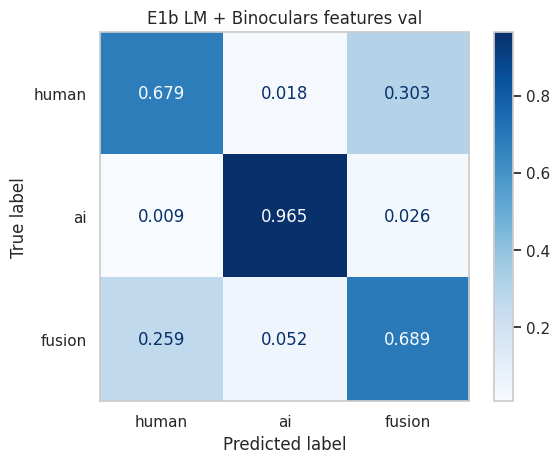

In [9]:
import lightgbm as lgb
LGB = dict(n_estimators=600, learning_rate=0.03, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
           colsample_bytree=0.8, random_state=SEED, verbose=-1)  # fixed, no early stopping on val
for name, cols in [('E1: LM + stylometry features only (LightGBM)', FEATS), ('E1b: LM + stylometry + Binoculars (LightGBM)', FEATS + BINO)]:
    p_e1 = lgb.LGBMClassifier(**LGB).fit(F_tr[cols], ppl_tr.y).predict(F_va[cols])
    summary.append({'experiment': name, 'val_macro_f1': macro_f1(val.y, p_e1)})
    print(summary[-1])
report(val.y, p_e1, 'E1b LM + Binoculars features val')

**Observations.** Binoculars adds signal on its own: E1b 0.777 vs E1 0.761 (+0.017), mostly on the hard classes (human 0.646 → 0.672, fusion 0.682 → 0.701). On its own it is still far below the encoders.

## E2 — stacking with out-of-fold predictions inside val

Base models were trained without val, so their val outputs are honest inputs for a meta-model. 5-fold group CV on val gives out-of-fold (OOF) predictions; test predictions are the average of the 5 fold models.

{'experiment': 'E2a: stack base models (encoders + TF-IDF)', 'val_macro_f1': 0.9701893005822658}
{'experiment': 'E2b: stack base models + LM/stylometry', 'val_macro_f1': 0.9701722714931221}
{'experiment': 'E2c: stack base models + LM/stylometry + Binoculars', 'val_macro_f1': 0.970489735266264}
Stack 04b OOF val: macro-F1 = 0.9705
              precision    recall  f1-score   support

       human     0.9356    0.9707    0.9528      6723
          ai     0.9980    0.9974    0.9977     12239
      fusion     0.9751    0.9471    0.9609      8489

    accuracy                         0.9753     27451
   macro avg     0.9696    0.9717    0.9705     27451
weighted avg     0.9757    0.9753    0.9753     27451



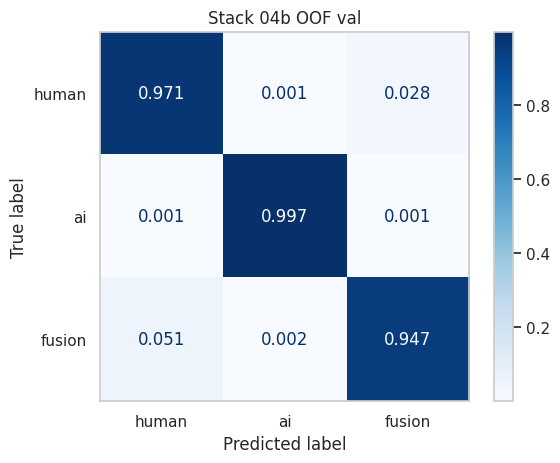

,macro_f1,n
domain,,
arxiv_papers,0.9746,1378
blog_authorship_corpus,0.8985,4004
bundestag,0.9781,5343
cnn_news,0.9934,4436
euro_court_cases,0.9812,2776
gutenberg,0.9927,723
house_of_commons,0.9848,3117
student_essays,0.9824,5674


In [10]:
from sklearn.model_selection import StratifiedGroupKFold
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(val, val.label + val.lang + val.domain, val.group))
val['fold'] = -1
for k, (_, v) in enumerate(folds):
    val.loc[v, 'fold'] = k

LGB_STACK = dict(n_estimators=1000, learning_rate=0.02, num_leaves=31, min_child_samples=30, subsample=0.8, subsample_freq=1,
                 colsample_bytree=0.5, reg_lambda=1.0, random_state=SEED, verbose=-1)
def stack(cols):
    X, Xt = pd.concat([val[BASE_COLS], F_va], axis=1)[cols], pd.concat([test[BASE_COLS], F_te], axis=1)[cols]
    oof, pt, models = np.zeros((len(val), 3)), np.zeros((len(test), 3)), []
    for tr_i, va_i in folds:
        m = lgb.LGBMClassifier(**LGB_STACK).fit(X.iloc[tr_i], val.y.iloc[tr_i])
        oof[va_i] = m.predict_proba(X.iloc[va_i]); pt += m.predict_proba(Xt) / len(folds); models.append(m)
    return oof, pt, models, X

runs = {'E2a: stack base models (encoders + TF-IDF)': BASE_COLS + ['lang', 'domain'],
        'E2b: stack base models + LM/stylometry': BASE_COLS + FEATS,
        'E2c: stack base models + LM/stylometry + Binoculars': BASE_COLS + FEATS + BINO}
stacked = {}
for name, cols in runs.items():
    stacked[name] = stack(cols)
    summary.append({'experiment': name, 'val_macro_f1': macro_f1(val.y, stacked[name][0].argmax(1))})
    print(summary[-1])
STACK = max(runs, key=lambda n: macro_f1(val.y, stacked[n][0].argmax(1)))
oof, p_test, models, X_stack = stacked[STACK]
report(val.y, oof.argmax(1), 'Stack 04b OOF val')
display(f1_by(val.assign(pred=oof.argmax(1)), 'pred', 'domain'))

**Observations (E2).** With the 03c specialist as an extra input, the base stack (E2a) improves from 0.9673 (04) to **0.9702**. On top of that, LM/stylometry features add nothing (E2b 0.9702) and Binoculars adds +0.0003 (E2c 0.9705). These differences are within noise (0.001 ≈ 30 val rows), so once strong encoders are stacked, the LM-based features are redundant. Best stack: **0.9705**, +0.040 over the 03b reference.

## E3 — per-class weights for macro-F1 (tuned on folds 0–2, checked on folds 3–4, and swapped)

In [11]:
import itertools
GRID = np.round(np.linspace(0.5, 2.0, 16), 3)
def tune(p, y):
    return max(([1.0, a, f] for a, f in itertools.product(GRID, GRID)), key=lambda w: macro_f1(y, (p * w).argmax(1)))

A, B = val.fold.isin([0, 1, 2]).values, val.fold.isin([3, 4]).values
honest = []
for fit_m, ev_m in [(A, B), (B, A)]:
    w = tune(oof[fit_m], val.y.values[fit_m])
    honest.append(macro_f1(val.y.values[ev_m], (oof[ev_m] * w).argmax(1)) - macro_f1(val.y.values[ev_m], oof[ev_m].argmax(1)))
W = tune(oof, val.y.values)
print('held-out gain from weights:', np.round(honest, 4), '| final weights (human, ai, fusion):', W)
summary.append({'experiment': f'E3: {STACK.split(":")[0]} + class weights (OOF, optimistic)', 'val_macro_f1': macro_f1(val.y, (oof * W).argmax(1))})
summary.append({'experiment': 'E3: held-out gain of weights (mean of 2 halves)', 'val_macro_f1': float(np.mean(honest))})

held-out gain from weights: [0.     0.0003] | final weights (human, ai, fusion): [1.0, np.float64(0.9), np.float64(0.5)]


**Observations (E3).** The held-out gain of class weights is again about zero (0.000 and +0.0003). Because the mean is just above 0, the code keeps the weights (human 1.0, ai 0.9, fusion 0.5). They move about 0.4% of test predictions from fusion to human, so `submission_final_04b.csv` and `submission_stack_04b.csv` should score about the same.

## Summary and submissions

In [12]:
res = pd.DataFrame(summary).round(4)
res.to_csv(OUT / 'results_summary_04b.csv', index=False)
display(res)

def save(probs, name):
    pred = pd.DataFrame({'id': test.id, 'label': np.array(LABELS)[probs.argmax(1)]})
    s = sub[['id']].merge(pred, on='id', how='left')
    assert len(s) == len(sub) and s.label.isin(LABELS).all()
    s.to_csv(OUT / name, index=False)
    print(name, s.label.value_counts(normalize=True).round(3).to_dict())

use_w = np.mean(honest) > 0  # only keep the weights if they helped on held-out folds
save(p_test, 'submission_stack_04b.csv')
save(p_test * (W if use_w else 1), 'submission_final_04b.csv')
print('final = stack', '+ class weights' if use_w else '(weights did not help on held-out folds)')

,experiment,val_macro_f1
0,"TF-IDF baseline, 60k (02)",0.8796
1,"TF-IDF baseline, full (02b)",0.8984
2,"encoder, 40k (03)",0.8999
3,"encoder, full (03b)",0.9305
4,"REFERENCE = encoder, full (03b)",0.9305
5,E1: LM + stylometry features only (LightGBM),0.7607
6,E1b: LM + stylometry + Binoculars (LightGBM),0.7774
7,E2a: stack base models (encoders + TF-IDF),0.9702
8,E2b: stack base models + LM/stylometry,0.9702
9,E2c: stack base models + LM/stylometry + Binoc...,0.9705


submission_stack_04b.csv {'ai': 0.514, 'human': 0.26, 'fusion': 0.226}
submission_final_04b.csv {'ai': 0.514, 'human': 0.264, 'fusion': 0.222}
final = stack + class weights


**Summary.** Reference (03b encoder, head+tail) 0.9305 → stack of encoders + TF-IDF + 03c specialist + LM/Binoculars features **0.9705** (OOF on the fixed val split). What helped: more training data (02 → 02b, 03 → 03b), head+tail over head/chunks, stacking with 03b window statistics, and the human-vs-fusion specialist. What did not: chunk averaging as a predictor, LM/Binoculars features once encoders are stacked, and class weights.

In [13]:
import joblib
joblib.dump({'models': models, 'cols': list(X_stack.columns), 'weights': W if use_w else [1, 1, 1]}, OUT / 'stacker_04b.joblib')
X_stack.assign(id=val.id.values, y=val.y.values).to_csv(OUT / 'stack_val_features_04b.csv', index=False)